# Understanding and Testing Randomized Algorithms

The goal for this notebook is to sketch some ideas for how to think about testing randomized algorithms ---especially the kinds of algorithms that we use for probabilistic inference.  In practice, randomized algorithms are hard to work with because they are unpredictable.  However, in theory, their unpredictability is a feature rather than a bug, as it allows us to obtain useful guarantees, such as unbiasedness, often while being computationally efficient.  But randomized algorithms and their theoretical guarantees (e.g., unbiasedness, consistency, proper weighting) are a little nuanced and hard to wrap our heads around. 

Setting expectations: This notebook is not sufficiently "mature" to give specific recommendations. Still, I hope it's at least a starting point for discussion and for surfacing some of the challenges and subtleties of randomized algorithms.  In other words, my goal is to plant the right seeds in your brains so that you'll make well-informed choices.

There were a lot of concepts that we talked about during the original mentorship sessions that we haven't written down, but would be good to do so, even as stubs.

A partial list:

 * "sensitivity" of a testing strategy / how precise is the instrument that we are using to conduct the test? (e.g., it's hard to test microscopic errors without a microscope.)  Monte Carlo averaging is among the bluntest of instruments for testing---it is hard to beat in the real world, but in software, we can almost always find ways to beat it.  Freezing the random number generator makes your code deterministic, but it is at best a regression test and very brittle.  Note that randomness is a feature, not a bug, in many of these algorithms.

Flavors of testing:
 * Property-based testing
 * Regression testing
 * Unit testing
 * Integration testing

In [ ]:
%load_ext autoreload
%autoreload 2

In [ ]:
import numpy as np
from arsenal.maths import random_dist, sample_dict, sample

[Note for future: Consider simpler jumping off points, i.e., an easier algorithm.]

Suppose we have the following tricky little sampling algorithm from our recent [AWRS paper](https://arxiv.org/abs/2504.05410).

I encourage you to try injecting errors into this code to see if you can detect them with the testing strategies that we develop.

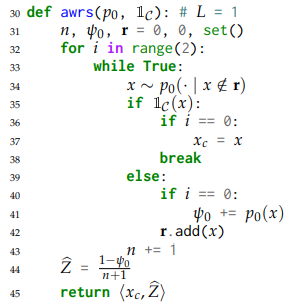

Here is a translation into Python:

In [ ]:
def awrs(p, cond, draw=lambda p, context='': sample(p)):
    p_cond = p.copy()
    n, psi = 0, 0
    xc0 = None
    for i in range(2):
        while True:
            x = draw(p_cond / p_cond.sum(), context=('awrs', i, xc0))
            if cond(x):
                if i == 0:
                    xc0 = x
                break
            else:
                if i == 0:
                    psi += p_cond[x]
                p_cond[x] = 0
            n += 1
    return xc0, (1 - psi) / (n + 1)

Did we implement it correctly?

Well... what is it *supposed to do*?

It is supposed to generate "properly weighted samples for the distribution $\widetilde{p} = Z \, p$"

Let's try to unpack that a bit.  Here is some additional stuff from the paper (or at least some earlier draft of it).

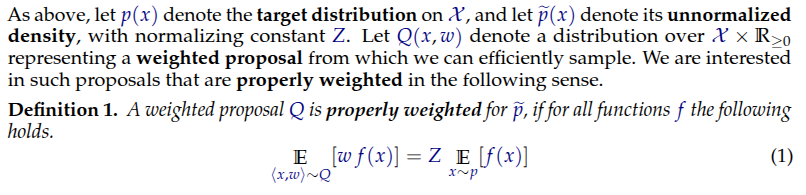

This definition has some mathematical ridiculousness.  How do we enumerate all possible functions in order to check that $Q=\texttt{AWRS}$ is properly weighted?  Fortunately, this all functions nonsense is just a technical thing that is needed when $\mathcal{X}$ is uncountable.  For our purposes, it is sufficient to take $f(x)$ to be the vector-wise indicator for the domain $\mathcal{X}$.  You should convince yourself of this.  

Here is a more precise statement / alternative definition of proper weighting that is suitable for our purposes:
$$
\mathop{\mathbb{E}}_{(x,w) \sim Q} \left[ w 1[x = x'] \right]
= 
Z \mathop{\mathbb{E}}_{x \sim p} \left[ 1[x = x'] \right]
\quad\text{ for all }
x' \in \mathcal{X}:
$$

Note that you may often need to tweak definitions, narrow/broaden the scope of theory in order to suit your codes intended use cases.

Now that we have a definition of proper weighting that we are relatively happy with we need to think about which things in the equation we can compute and which things we need to estimate.

Let's make a test case.  (Note that `p` below isn't the same as the $p$ above because that one is constrained that this one is not.)

In [ ]:
np.random.seed(0)
N = 4
p = random_dist(N)
p /= p.sum()
cond = np.random.uniform(0,1,size=N) < .5

Z = p[cond].sum()
target = p * cond         # NOTE: not normalized
#posterior = target / Z

print(f'{p      = }')
print(f'{cond   = }')
print(f'{target = }')

Let's do a quick run run throught the AWRS algorithm.

In [ ]:
(item, w) = awrs(p, lambda x: cond[x])
print(item, w)

### First idea

The obvious first testing strategy that we might try is to run the code "a lot of times" and essentially compute an average.

In [ ]:
np.random.seed(0)
reps = 1_000
have = np.zeros_like(p)

xs = []; ys = []
for r in iterview(range(1, 1+reps)):
    (x, w) = awrs(p, lambda x: cond[x])
    have[x] += w

print(abs(have / reps - target).sum())

Is this error small enough?  How do you know?

### Next idea?

Watch error decrease as a function of the number of samples.  I.e., it should keep going down *forever*, modulo numerical percision.

In [ ]:
np.random.seed(0)
M = 10_000
have = np.zeros_like(p)

xs = []; ys = []
for r in iterview(range(1, 1+M)):
    (item, w) = awrs(p, lambda x: cond[x])
    have[item] += w
    if r >= 20:
        xs.append(r)
        ys.append(abs(have / r - target).sum())

In [ ]:
pl.plot(xs, ys); pl.loglog(); pl.xlabel('number of samples (log scale)'); pl.ylabel('error (log scale)');

What did we expect to see?

Hint: Why did I use a log-log scale?

What are the theoretical values for the slope and intercept (assuming Monte Carlo estimation from IID samples)?

We know that the variance of a Monte Carlo estimator $\mathrm{Var}(\frac{1}{M} \sum_{m=1}^M X^{(m)}) = \mathrm{Var}(X) / M$ where $X^{(1)}, \ldots, X^{(M)}$ are i.i.d. samples from some distribution.

Given that Monte Carlo is unbiased.

It's root-mean-square-error $\sqrt{ \mathbb{E}_{X^{(1)}, \ldots X^{(M)}} (\overline{X} - \frac{1}{M} \sum_{m=1}^M X^{(m)} )^2 } = \text{bias}^2 + \text{variance} = \sqrt{\mathrm{Var}(X) / M}$.



In [ ]:
slope, intercept = np.polyfit(np.log(xs), np.log(ys), deg=1)
pl.plot(np.log(xs), np.log(ys)); pl.plot(np.log(xs), np.log(xs) * slope + intercept, c='r', lw=2, 
                                         label=f'log error = {slope:.2f} log(r) + {intercept:.2f}');
pl.legend();

Below, we extend this plotting experiment to average the squiggly lines over multiple runs.  Then, we can see the average performance looking closer to the theoretical line.

In [ ]:
np.random.seed(0)
reps = 1000
M = 50
ms = list(range(1, 1 + M))
runs_ys = []
samples = []
for r in iterview(range(1, 1+reps)):
    ys = []
    have = np.zeros_like(p)
    for m in ms:
        # Each sample from the AWRS is essentially a one-hot distribution whose expected value equals `target`
        (item, w) = awrs(p, lambda x: cond[x])
        have[item] += w

        onehot = np.zeros_like(target)
        onehot[item] = w
        
        samples.append(onehot)

        # Note that the theory is sensitive to the choice of vector-wise error (e.g., using L1 here 
        # affects the theoretical curve's intercept)
        ys.append(np.linalg.norm(have / m - target)**2)
    runs_ys.append(ys)
runs_ys = np.array(runs_ys)

In [ ]:
from arsenal.maths import mean_confidence_interval

Because we have a multi dimensional object, we have something a little more complicated that the standard deviation as our multiplier.

In [ ]:
C = np.cov(np.array(samples).T)
V = np.trace(C)

In [ ]:
cis = [mean_confidence_interval(runs_ys[:,m]) for m in range(M)]
pl.plot(ms, [ci.mean for ci in cis], c='b')
pl.fill_between(ms, [ci.lower for ci in cis], [ci.upper for ci in cis], alpha=0.2, color='b', label='observed')
for r in range(min(20, reps)): pl.plot(ms, runs_ys[r], alpha=0.1, c='k', zorder=-1, label='run' if r == 0 else None)
pl.plot(ms, V / np.array(ms), label=r'theoretical', c='orange', zorder=10, lw=2, linestyle=':')
pl.xlabel(r'number of samples ($M$)')
pl.ylabel('mean squared error')
pl.loglog(); pl.legend();

So what did we *actually* accomplish with this plot? This plot lets us "eyeball" that the mean squared error is decreasing at the theoretical rate of $1/M$.  Root mean square error would be $1/\sqrt{M}$.  In order to turn this into software tests, what would you do?

How would we test of the samples are unbiased? consistent? properly weighted?

### Program Tracing

Below is some code for that hijacks the random variable generation in some program to make it enumerate all possible combinations (we call those combinations traces), and to track each trace's probability.  [This is done with a fairly simple trie data structure that mirrors the kind of trie used for caching in `genlm-backend`.]

In [ ]:
import html

import numpy as np
from arsenal import Integerizer, colors
from arsenal.maths import sample
from graphviz import Digraph


def separate_keys_vals(x):
    from genparse.lm import LazyProb

    if isinstance(x, LazyProb):
        return x.keys(), x.values()
    elif isinstance(x, np.ndarray):
        return range(len(x)), x
    else:
        return list(x.keys()), np.array(list(x.values()))


class Tracer:
    """
    This class lazily materializes the probability tree of a generative process by program tracing.
    """

    def __init__(self):
        self.root = Node(idx=-1, mass=1.0, parent=None)
        self.cur = None

    def __call__(self, p, context=None):
        "Sample an action while updating the trace cursor and tree data structure."

        keys, p = separate_keys_vals(p)
        cur = self.cur

        if cur.child_masses is None:
            cur.child_masses = cur.mass * p
            cur.context = context

        if context is not None and context != cur.context:
            raise ValueError(f"""
ERROR: trace divergence detected:
trace context:   {self.cur.context}
calling context: {context}
""")         
        a = cur.sample()
        if a not in cur.active_children:
            cur.active_children[a] = Node(
                idx=a,
                mass=cur.child_masses[a],
                parent=cur,
                token=keys[a],
            )
        self.cur = cur.active_children[a]
        return keys[a]


class Node:

    def __init__(
        self,
        idx,
        mass,
        parent,
        token=None,
        child_masses=None,
        context=None,
    ):
        self.idx = idx
        self.mass = mass
        self.parent = parent
        self.token = token  # used for visualization
        self.child_masses = child_masses
        self.active_children = {}
        self.context = context
        self._mass = mass  # bookkeeping: remember the original mass

    def sample(self):
        return sample(self.child_masses)

    def p_next(self):
        return Float.chart((a, c.mass / self.mass) for a, c in self.children.items())

    def update(self):
        "Restore the invariant that self.mass = sum children mass."
        if self.parent is not None:
            self.parent.child_masses[self.idx] = self.mass
            self.parent.mass = np.sum(self.parent.child_masses)
            self.parent.update()

    def graphviz(
        self,
        fmt_edge=lambda x, a, y: f'{html.escape(str(a))}/{y._mass/x._mass:.2g}',
        fmt_node=lambda x: (
            (f'{x.context}\n' if x.context else '')
            +
            (f'{x.mass}/{x._mass:.2g}' if x.mass > 0 else f'{x._mass:.2g}')
        ),
    ):
        "Create a graphviz instance for this subtree"
        g = Digraph(
            graph_attr=dict(rankdir='LR'),
            node_attr=dict(
                fontname='Monospace',
                fontsize='10',
                height='.05',
                width='.05',
                margin='0.055,0.042',
            ),
            edge_attr=dict(arrowsize='0.3', fontname='Monospace', fontsize='9'),
        )
        f = Integerizer()
        xs = set()
        q = [self]
        while q:
            x = q.pop()
            xs.add(x)
            if x.child_masses is None:
                continue
            for a, y in x.active_children.items():
                a = y.token if y.token is not None else a
                g.edge(str(f(x)), str(f(y)), label=f'{fmt_edge(x,a,y)}')
                q.append(y)
        for x in xs:
            if x.child_masses is not None:
                g.node(str(f(x)), label=str(fmt_node(x)), shape='box')
            else:
                g.node(str(f(x)), label=str(fmt_node(x)), shape='box', fillcolor='gray')
        return g


class TraceSWOR(Tracer):
    """
    Sampling without replacement 🤝 Program tracing.
    """

    def __enter__(self):
        self.cur = self.root

    def __exit__(self, *args):
        self.cur.mass = 0  # we will never sample this node again.
        self.cur.update()  # update invariants

    def _repr_svg_(self):
        return self.root.graphviz()._repr_image_svg_xml()

    def __repr__(self):
        return self.root.graphviz().source


In [ ]:
tracer = TraceSWOR()
prob = np.zeros(N)
while tracer.root.mass > 0:
    with tracer:
        (item, w) = awrs(p, lambda x: cond[x], draw=tracer)
        prob[item] += w * tracer.cur.mass
    #print(tracer.root.mass)

In [ ]:
assert np.allclose(target, prob)

In [ ]:
abs(target-prob).sum()   # the difference is not zero, it rarely will be with floating point numbers

We can visualize the traces that we explored along with the `context` metadata

In [ ]:
tracer

In [ ]:
from genparse import EOS
from collections import namedtuple
from arsenal.maths import sample_dict

In [ ]:
Particle = namedtuple('Particle', 'weight, string')

In [ ]:
def sequential_importance_sampling(p, q, M, draw=sample_dict):
    unfinished = [Particle(1, ()) for _ in range(M)]
    finished = []
    while unfinished:
        next_unfinished = []
        for particle in unfinished:
            P = p.p_next(particle.string)
            Q = q.p_next(particle.string)
            x = draw(Q)
            if x == EOS:
                finished.append(Particle(particle.weight * P[x] / Q[x], particle.string))
            else:
                next_unfinished.append(Particle(particle.weight * P[x] / Q[x], particle.string + (x,)))
        unfinished = next_unfinished
    return finished

Let's ask ourselves again: what is the code supposed to do in theory because it is the theory that gives us the test cases as they characterized cross-sections of the intended behavior (there might be other important properties that we like of this algorithm that don't appear in this list of guarantees; for example, we know what the weights should equal and it is worth adding those kinds of sanity/spot checks as many implemention bugs can be caught that way).

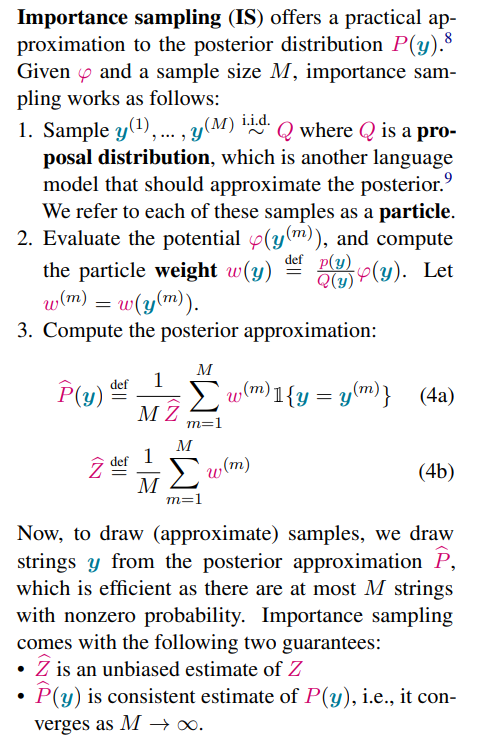

Since this is sequential important sampling, we need some way to generate sequences.  Below are some simple probabilistic context-free language models.  (Note that for the tracing strategy to terminate we need `q` language model to have finite support.  And for the method to be unbiased we require absolute continuity to hold.  Thus, `p` needs to be finite support as well.  I encourage you to play around with some of these options.)

In [ ]:
from genparse import EarleyLM
p = EarleyLM.from_string("""

0.3: S -> a a
0.6: S -> b b b
0.1: S ->

""")

q = EarleyLM.from_string("""

0.2: S -> a a
0.7: S -> b b b
0.1: S ->

""")

In [ ]:
finished = sequential_importance_sampling(p, q, M=3, draw=sample_dict)
finished

In [ ]:
tracer = TraceSWOR()
have = 0
while tracer.root.mass > 0:
    with tracer:
        M = 1
        finished = sequential_importance_sampling(p, q, M=M, draw=tracer)
        Z_hat = sum(particle.weight for particle in finished) / M
        have += Z_hat * tracer.cur.mass
    print(tracer.root.mass)

In [ ]:
have

In [ ]:
tracer

We can repeat this exercise in sequential importance resampling. 

In [ ]:
def sequential_importance_resampling(p, q, M, tau, draw=lambda p, context=None: sample_dict(p)):
    unfinished = [Particle(1, ()) for _ in range(M)]
    finished = []
    t = 0
    while True:
        t += 1
        next_unfinished = []
        for m, particle in enumerate(unfinished):
            P = p.p_next(particle.string)
            Q = q.p_next(particle.string)
            x = draw(Q, context=(t, m))
            if x == EOS:
                finished.append(Particle(particle.weight * P[x] / Q[x], particle.string))
            else:
                next_unfinished.append(Particle(particle.weight * P[x] / Q[x], particle.string + (x,)))
        unfinished = next_unfinished

        if not unfinished: break

        W = sum(particle.weight for particle in unfinished)
        W2 = sum(particle.weight**2 for particle in unfinished)
        M_eff = W**2 / W2

        if M_eff < tau * M:
            distr = {k: particle.weight / W for k, particle in enumerate(unfinished)}
            indices = [ 
                draw(distr, context=(f'resample', t, m))
                for m in range(M)
            ]
            avg_weight = W / M
            unfinished = [Particle(avg_weight, unfinished[k].string) for k in indices]
    
    return finished

In [ ]:
finished = sequential_importance_resampling(p, q, tau=1, M=3)
finished

Pro tip: Make sure the total mass decreases quickly, as the code below will halt only when the total mass is zero.  Note that mass will only go to true zero if the support of the distribution is finite.  Also, be aware that traces are a combinatorial space, so this strategy is only practical for smaller problems.  It may be a reasonable heuristic to stop the loop early if the remaining mass is small but nonzero.  There are some techniques to debias the truncated run.  Note that we will then have an unbiased estimate of the quantity rather than an exact enumeration.  There are some details related to getting that approach to work that I am happy to discuss anytime.  They are based on [this paper](https://arxiv.org/abs/2002.09067), which sadly scooped me, but they did a pretty great job (ps. I have a few extra tricks they are missing).

In [ ]:
tracer = TraceSWOR()
have = 0
while tracer.root.mass > 0:
    with tracer:
        M = 3
        finished = sequential_importance_resampling(p, q, tau=0.75, M=M, draw=tracer)
        Z_hat = sum(particle.weight for particle in finished) / M
        have += Z_hat * tracer.cur.mass
    print(tracer.root.mass)

In [ ]:
have

Notice that with resampling we have more traces that without.  This is because there are more places that request random decision in the code.

In [ ]:
tracer

## Some Miscellaneous Thoughts

Testing is fundamentally about control. Some abstractions give us more control over a system’s behavior than others, and good tests depend on choosing abstractions that make critical behaviors observable, reproducible, and manipulable. Of course, some tests are better than none, and not all behaviors are visible under a microscope. Some emerge only when viewed from “1,000 feet”—via integration tests, stress tests, or long-horizon statistical checks.

Abstraction and composition are aesthetically pleasing and often intellectually satisfying. Finding the right abstraction can take centuries in mathematics, and in software, the situation is similar—but with an added complication: every abstraction introduces more code paths and more configurations (some intentional, some accidental). So we should evaluate abstractions with a cost–benefit lens: they can greatly reduce conceptual burden and enable reuse, but they also create more cases to check, and occasionally hide rough edges.

Many abstractions imported from mathematics are elegant and well-understood, and they can be highly desirable in library design. But developers sometimes avoid them for practical reasons—efficiency, or the combinatorial cost of supporting all the interactions between components. (Contrast general CFGs with CFGs in Chomsky Normal Form: the full generality is clean mathematically, but often skipped in real implementations because it expands the API surface and the number of special cases.)

Some abstractions are leaky: they promise to hide complexity but fail to do so, forcing the user to understand the underlying machinery to get things to work. Leakage is not always terrible; it can be the unavoidable cost of simplification or the result of efficiency-motivated shortcuts.

So, which abstractions are worth having? A few candidates:

* General language-model interfaces.  Allowing arbitrary LMs gives maximal control: we can plug in special stub LMs to test edge cases, design LMs that guarantee termination, or use hand-crafted models with perfectly understood behavior. This can make tests faster, more interpretable, and more robust.

* String-level operations instead of token-ID–level operations. Working with strings is friendlier and easier to reason about, especially when writing tests or specifying expected behavior. But strings and Python lists/tuples are slower than raw PyTorch tensors. Choosing the level of abstraction affects both ergonomics and testability.